# 03 · Clustering bike-sharing stations (Part B)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code: station features from the status log and from trips, filtering, PCA, choice of K, KMeans, Ward/GMM comparison, profiles, maps, link to Part A, saved labels.
- Used only data before 1 June 2023, so the labels can feed notebook 04 without leaking the test period.
- Chose K = 5 from the metrics in section 5.

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- Stations removed by the filters get label −1 and are not analysed.

_Team notes:_

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.width", 200)
RNG = np.random.default_rng(7)
# station features use data before the supervised test period only, so labels can feed notebook 04 without leakage
CUTOFF = pd.Timestamp("2023-06-01")
cut_s = CUTOFF.timestamp()

trips = bc.load_clean("trips_clean")
status = bc.load_clean("status_clean")
meta = bc.load_clean("stations_meta").set_index("id")
cities = pd.read_csv(bc.DATA_DIR / "cities.csv").set_index("id")
trip_cl = bc.load_clean("trip_clusters")

## 1. Station features from the status log (hourly grid, local time)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Per station: mean fill (clipped at 1.5), share of hours empty, share of hours full, mean hourly change, records per day, maintenance share.
- Weekday 24-hour fill curve centred on each station's mean and reduced with PCA (first 2 scores kept); evening − morning fill; weekend − weekday fill.

**Not done by Claude**
- The weekend fill curve is not decomposed the same way.

In [2]:
g = bc.hourly_grid(status[status.time < cut_s])
g = g[g.valid & (g.maintenance == 0)].copy()
g = g.merge(meta[["city_id", "capacity", "virtual"]], left_on="station_id", right_index=True)
g["local"] = bc.local_time(g.hour_epoch * 3600, g.city_id.map(cities.timezone))
g = bc.add_calendar(g, "local")
g["fill"] = (g.bikes / g.capacity).clip(0, 1.5)
g["is_empty"] = g.bikes_available_to_rent == 0
g["is_full"] = ((g.free_racks + g.free_special_racks) == 0) & (g.virtual == 0)
g = g.sort_values(["station_id", "hour_epoch"])
g["abs_change"] = g.groupby("station_id").bikes_available_to_rent.diff().abs()
len(g)

10082999

In [3]:
sf = g.groupby("station_id").agg(
    valid_hours=("fill", "size"),
    mean_fill=("fill", "mean"),
    p_empty=("is_empty", "mean"),
    p_full=("is_full", "mean"),
    hourly_volatility=("abs_change", "mean"),
    records=("obs_idx", lambda x: x.max() - x.min() + 1),
)
sf["records_per_day"] = sf.records / (sf.valid_hours / 24)
mshare = status[status.time < cut_s].groupby("station_id").maintenance.mean().rename("maintenance_share")
sf = sf.join(mshare)
sf.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
valid_hours,2749.0,3667.879,2132.100,1.000,1749.000,3587.000,5974.000,6394.000
mean_fill,2749.0,0.369,0.165,0.000,0.253,0.343,0.463,1.020
p_empty,2749.0,0.100,0.142,0.000,0.003,0.047,0.133,1.000
p_full,2749.0,0.068,0.174,0.000,0.000,0.000,0.030,1.000
hourly_volatility,2738.0,0.137,0.190,0.000,0.039,0.075,0.161,4.990
records,2749.0,755.598,1247.937,1.000,120.000,337.000,842.000,15236.000
records_per_day,2749.0,5.085,9.229,0.147,1.215,2.138,4.850,145.509
maintenance_share,2749.0,0.002,0.038,0.000,0.000,0.000,0.000,0.989


profile PCA explained: [0.666 0.183 0.05  0.026 0.016 0.015]


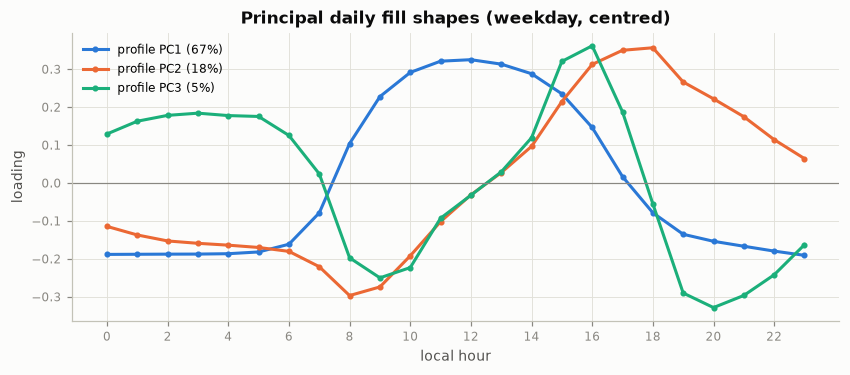

In [4]:
# weekday daily fill profile, centred on each station's mean -> shape of the daily cycle
prof = g[g.weekend == 0].groupby(["station_id", "hour"]).fill.mean().unstack()
prof = prof[prof.notna().sum(axis=1) == 24]
prof_c = prof.sub(prof.mean(axis=1), axis=0)
ppca = PCA(n_components=6).fit(prof_c)
print("profile PCA explained:", ppca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(figsize=(9, 3.4))
for i in range(3):
    ax.plot(range(24), ppca.components_[i], marker="o", ms=3, label=f"profile PC{i+1} ({ppca.explained_variance_ratio_[i]:.0%})")
ax.axhline(0, color=bc.GREY, lw=.8)
ax.set(title="Principal daily fill shapes (weekday, centred)", xlabel="local hour", ylabel="loading", xticks=range(0, 24, 2))
ax.legend()
plt.show()

In [5]:
pscore = pd.DataFrame(ppca.transform(prof_c)[:, :2], index=prof_c.index, columns=["fill_shape_pc1", "fill_shape_pc2"])
# a direct, readable shape measure as well: evening minus morning fill
swing = (prof[[17, 18, 19]].mean(axis=1) - prof[[6, 7, 8]].mean(axis=1)).rename("fill_pm_minus_am")
wk = g.groupby(["station_id", "weekend"]).fill.mean().unstack()
wkend = (wk[1] - wk[0]).rename("fill_weekend_minus_weekday")
sf = sf.join(pscore).join(swing).join(wkend)
sf[["fill_shape_pc1", "fill_shape_pc2", "fill_pm_minus_am"]].corr().round(3)

,fill_shape_pc1,fill_shape_pc2,fill_pm_minus_am
fill_shape_pc1,1.000,0.000,-0.067
fill_shape_pc2,0.000,1.000,0.963
fill_pm_minus_am,-0.067,0.963,1.000


## 2. Station features from trips

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Departures, arrivals, median distance and duration, e-bike/weekend/free-end/AM/evening shares, AM/PM/overall net flow (with +5 shrinkage), trips per day.

**Not done by Claude**
- `trips_per_day` divides by the same calendar span (26 Aug 2022 – 1 Jun 2023) for every station, not by each station's own active period.

In [6]:
tr = trips[trips.time_start < cut_s]
tr = tr.assign(end_hour=(tr.start_local + pd.to_timedelta(tr.duration, "s")).dt.hour)
dep = tr.dropna(subset=["station_id_start"]).groupby("station_id_start")
arr = tr.dropna(subset=["station_id_end"]).groupby("station_id_end")
tf = pd.DataFrame({
    "departures": dep.size(), "arrivals": arr.size(),
    "dep_median_km": dep.distance.median() / 1000,
    "dep_median_min": dep.duration.median() / 60,
    "dep_ebike_share": dep.ebike.mean(),
    "dep_weekend_share": dep.weekend.mean(),
    "dep_end_free_share": dep.end_free.mean(),
    "dep_peak_am_share": dep.hour.apply(lambda h: h.between(6, 9).mean()),
    "dep_evening_share": dep.hour.apply(lambda h: h.between(16, 19).mean()),
}).fillna({"departures": 0, "arrivals": 0})
tf.index.name = "station_id"
wd = tr[tr.weekend == 0]
am_dep = wd[wd.hour.between(6, 9)].station_id_start.value_counts()
am_arr = wd[wd.end_hour.between(6, 9)].station_id_end.value_counts()
pm_dep = wd[wd.hour.between(16, 19)].station_id_start.value_counts()
pm_arr = wd[wd.end_hour.between(16, 19)].station_id_end.value_counts()
am = pd.concat({"d": am_dep, "a": am_arr}, axis=1).fillna(0)
pm = pd.concat({"d": pm_dep, "a": pm_arr}, axis=1).fillna(0)
tf["am_net"] = ((am.a - am.d) / (am.a + am.d + 5)).reindex(tf.index)   # +5 shrinks tiny stations towards 0
tf["pm_net"] = ((pm.a - pm.d) / (pm.a + pm.d + 5)).reindex(tf.index)
tf["net_flow"] = (tf.arrivals - tf.departures) / (tf.arrivals + tf.departures + 5)
days = (CUTOFF - pd.Timestamp("2022-08-26")).days
tf["trips_per_day"] = (tf.departures + tf.arrivals) / days
tf.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
departures,4281.0,187.050,409.769,0.000,2.000,36.000,195.000,6650.000
arrivals,4281.0,181.224,381.432,0.000,7.000,43.000,195.000,6343.000
dep_median_km,3525.0,2.053,1.752,0.075,1.100,1.574,2.360,19.751
dep_median_min,3525.0,20.599,29.028,3.000,10.000,14.000,20.000,474.000
dep_ebike_share,3525.0,0.145,0.333,0.000,0.000,0.000,0.000,1.000
dep_weekend_share,3525.0,0.255,0.204,0.000,0.136,0.233,0.333,1.000
dep_end_free_share,3525.0,0.098,0.176,0.000,0.000,0.033,0.111,1.000
dep_peak_am_share,3525.0,0.158,0.180,0.000,0.027,0.112,0.222,1.000
dep_evening_share,3525.0,0.300,0.218,0.000,0.177,0.277,0.375,1.000
am_net,3107.0,-0.027,0.450,-0.965,-0.375,0.000,0.286,0.967


## 3. Assemble and filter

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Filters: ≥ 30 valid days, maintenance < 50%, a complete 24-hour profile, ≥ 30 trips. log1p on skewed features; remaining NaN filled with the median.

**Not done by Claude**
- The filter thresholds were not tuned or tested for sensitivity.

In [7]:
meta["dist_centre_km"] = bc.haversine_m(meta.lat, meta.lon, meta.city_id.map(cities.lat), meta.city_id.map(cities.lon)) / 1000
F = sf.join(tf, how="left").join(meta[["city_id", "capacity", "virtual", "dist_centre_km", "terminal_type", "lat", "lon"]])
print("stations with status features:", len(F))
F = F[(F.valid_hours >= 24 * 30) & (F.maintenance_share < 0.5) & F.fill_shape_pc1.notna()]
F = F[(F.departures + F.arrivals) >= 30]
print("kept for clustering:", len(F))

stations with status features: 2749
kept for clustering: 2269


0 missing after fill


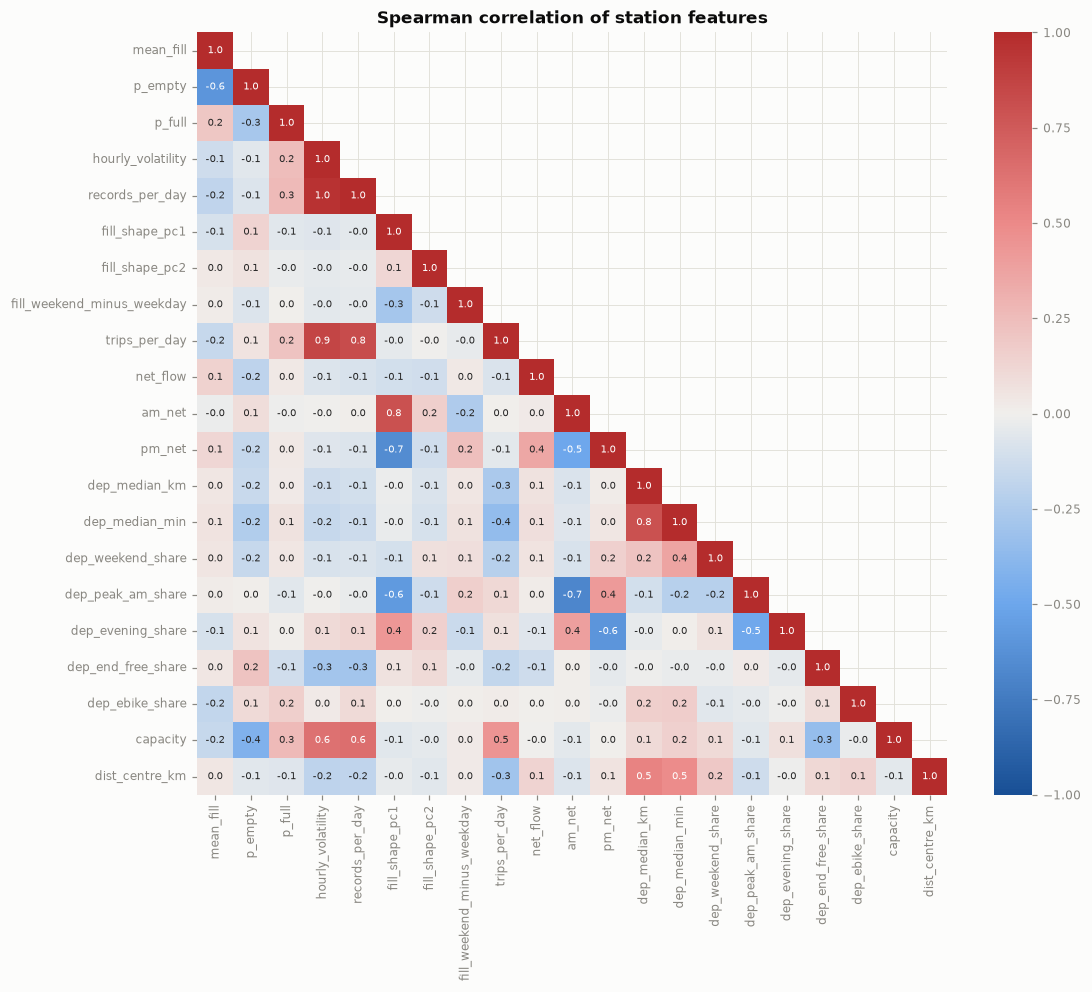

In [8]:
FEATS = ["mean_fill", "p_empty", "p_full", "hourly_volatility", "records_per_day",
         "fill_shape_pc1", "fill_shape_pc2", "fill_weekend_minus_weekday",
         "trips_per_day", "net_flow", "am_net", "pm_net",
         "dep_median_km", "dep_median_min", "dep_weekend_share", "dep_peak_am_share", "dep_evening_share",
         "dep_end_free_share", "dep_ebike_share",
         "capacity", "dist_centre_km"]
LOG = ["records_per_day", "trips_per_day", "capacity", "dist_centre_km", "hourly_volatility"]
Xs = F[FEATS].copy()
for c in LOG:
    Xs[c] = np.log1p(Xs[c])
Xs = Xs.fillna(Xs.median())
print(Xs.isna().sum().sum(), "missing after fill")
fig, ax = plt.subplots(figsize=(11, 9))
c = Xs.corr(method="spearman")
sns.heatmap(c, cmap=bc.DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".1f", annot_kws={"size": 6.5}, ax=ax,
            mask=np.triu(np.ones_like(c, bool), k=1))
ax.set_title("Spearman correlation of station features")
plt.show()

_Team notes:_

## 4. PCA

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- PCA on 21 standardised features; components with eigenvalue > 1 (Kaiser) are kept and used for clustering. Loadings and correlation circle.

**Not done by Claude**
- No rotation.

In [9]:
scaler = StandardScaler().fit(Xs)
Z = scaler.transform(Xs)
pca = PCA().fit(Z)
ev = pd.DataFrame({"explained": pca.explained_variance_ratio_, "cumulative": pca.explained_variance_ratio_.cumsum(),
                   "eigenvalue": pca.explained_variance_}, index=[f"PC{i+1}" for i in range(Z.shape[1])])
N_PC = int((ev.eigenvalue > 1).sum())
print("components with eigenvalue > 1 (Kaiser):", N_PC, "| cumulative:", ev.cumulative.iloc[N_PC - 1].round(3))
ev.head(10).round(3)

components with eigenvalue > 1 (Kaiser): 7 | cumulative: 0.691


,explained,cumulative,eigenvalue
PC1,0.173,0.173,3.637
PC2,0.157,0.330,3.305
PC3,0.108,0.439,2.276
PC4,0.085,0.524,1.784
PC5,0.060,0.584,1.259
PC6,0.057,0.640,1.188
PC7,0.051,0.691,1.066
PC8,0.044,0.735,0.925
PC9,0.041,0.776,0.862
PC10,0.039,0.815,0.816


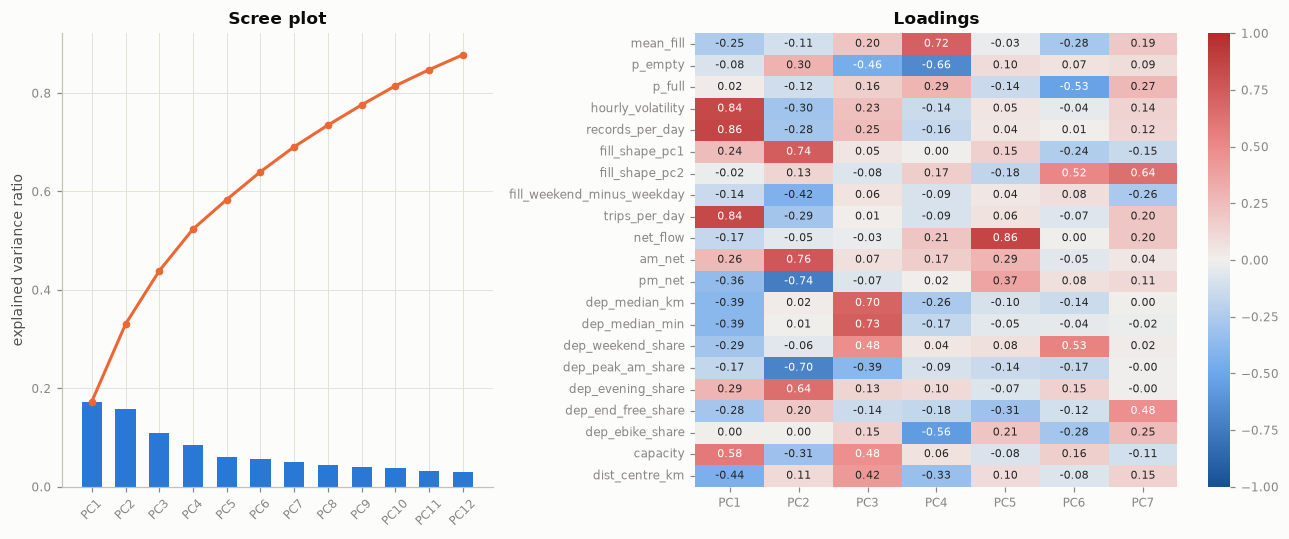

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].bar(ev.index[:12], ev.explained[:12], color=bc.SERIES[0], width=.6)
ax[0].plot(ev.index[:12], ev.cumulative[:12], color=bc.SERIES[1], marker="o", ms=4)
ax[0].set(title="Scree plot", ylabel="explained variance ratio")
ax[0].tick_params(axis="x", rotation=45)
load = pd.DataFrame(pca.components_[:N_PC].T * np.sqrt(pca.explained_variance_[:N_PC]), index=FEATS,
                    columns=[f"PC{i+1}" for i in range(N_PC)])
sns.heatmap(load, cmap=bc.DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax[1])
ax[1].set_title("Loadings")
plt.tight_layout()
plt.show()

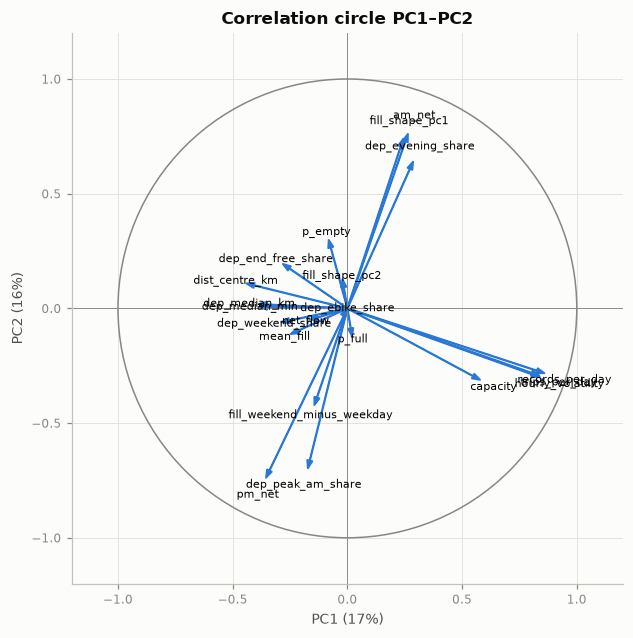

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=bc.GREY, lw=1))
for v in FEATS:
    x, y = load.loc[v, "PC1"], load.loc[v, "PC2"]
    ax.arrow(0, 0, x, y, color=bc.SERIES[0], width=.003, head_width=.025, length_includes_head=True)
    ax.text(x * 1.1, y * 1.1, v, fontsize=7, ha="center", va="center")
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal", title="Correlation circle PC1–PC2",
       xlabel=f"PC1 ({ev.explained.iloc[0]:.0%})", ylabel=f"PC2 ({ev.explained.iloc[1]:.0%})")
ax.axhline(0, color=bc.GREY, lw=.6)
ax.axvline(0, color=bc.GREY, lw=.6)
plt.show()

In [12]:
P = pca.transform(Z)[:, :N_PC]

_Team notes:_

## 5. Number of clusters and algorithm comparison

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- KMeans for k = 2..10 with silhouette, DB, CH and GMM BIC; bootstrap stability (20 fits on 80% subsamples); Ward dendrogram; final K = 5 with ids ordered by trips per day; ARI against Ward and GMM.

**Not done by Claude**
- Density-based methods (DBSCAN/HDBSCAN) were not tried.

In [13]:
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=20, random_state=0).fit(P)
    gm = GaussianMixture(k, covariance_type="full", n_init=3, random_state=0).fit(P)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(P, km.labels_),
                 "davies_bouldin": davies_bouldin_score(P, km.labels_), "calinski_harabasz": calinski_harabasz_score(P, km.labels_),
                 "gmm_bic": gm.bic(P), "smallest": np.bincount(km.labels_).min()})
sel = pd.DataFrame(rows).set_index("k")
sel.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz,gmm_bic,smallest
k,,,,,,
2,27648.886,0.184,1.955,432.090,52232.134,713
3,24335.983,0.158,1.832,399.584,51557.072,517
4,21827.859,0.159,1.674,383.621,51181.448,365
5,20262.236,0.136,1.686,353.544,50917.670,224
6,18979.191,0.149,1.581,332.419,50880.342,184
7,18028.795,0.160,1.510,311.364,50910.809,85
8,17226.206,0.139,1.648,294.244,50830.849,86
9,16328.032,0.146,1.522,287.046,50892.996,76
10,15697.311,0.148,1.472,275.371,50890.828,75


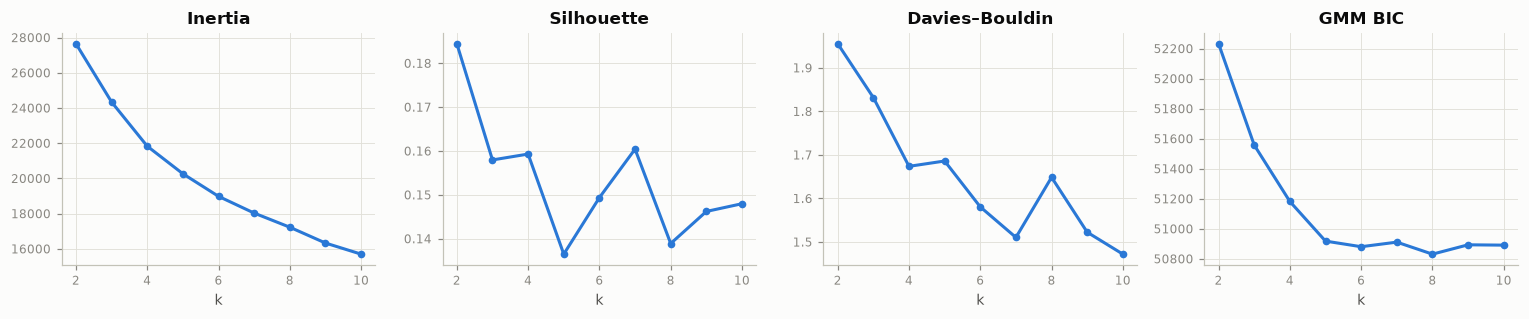

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, col, title in zip(ax, ["inertia", "silhouette", "davies_bouldin", "gmm_bic"],
                         ["Inertia", "Silhouette", "Davies–Bouldin", "GMM BIC"]):
    a.plot(sel.index, sel[col], marker="o", ms=4)
    a.set(title=title, xlabel="k")
plt.tight_layout()
plt.show()

In [15]:
# bootstrap stability: refit on 80% subsamples, compare on all stations
stab = {}
for k in range(2, 9):
    labs = [KMeans(k, n_init=10, random_state=b).fit(P[RNG.choice(len(P), int(.8 * len(P)), replace=False)]).predict(P)
            for b in range(20)]
    aris = [adjusted_rand_score(labs[i], labs[j]) for i in range(20) for j in range(i + 1, 20)]
    stab[k] = {"mean_ARI": np.mean(aris), "p10_ARI": np.percentile(aris, 10)}
pd.DataFrame(stab).T.round(3)

,mean_ARI,p10_ARI
2,0.893,0.798
3,0.803,0.654
4,0.841,0.738
5,0.790,0.653
6,0.804,0.705
7,0.637,0.468
8,0.646,0.461


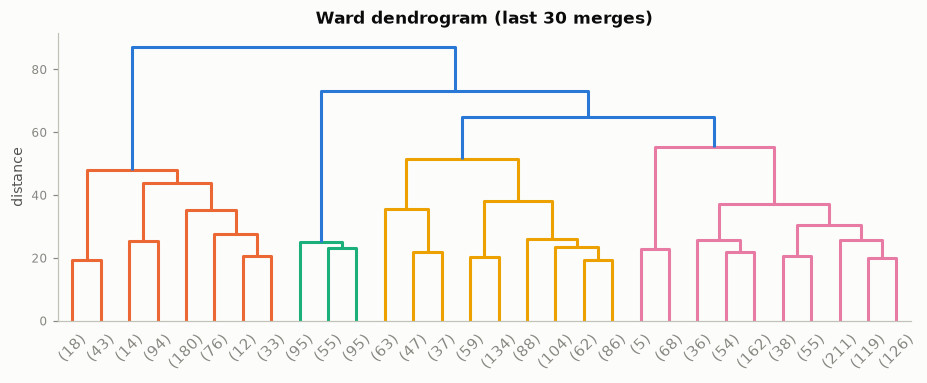

In [16]:
Lw = linkage(P, method="ward")
fig, ax = plt.subplots(figsize=(10, 3.4))
dendrogram(Lw, truncate_mode="lastp", p=30, ax=ax, color_threshold=None, above_threshold_color=bc.SERIES[0])
ax.set(title="Ward dendrogram (last 30 merges)", ylabel="distance")
ax.grid(False)
plt.show()

In [17]:
K = 5
km = KMeans(K, n_init=50, random_state=0).fit(P)
# order clusters by trips_per_day for readable ids
order = pd.Series(Xs.trips_per_day.values).groupby(km.labels_).mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
F["station_cluster"] = pd.Series(km.labels_).map(remap).values
ward = fcluster(Lw, K, criterion="maxclust")
gmm = GaussianMixture(K, covariance_type="full", n_init=5, random_state=0).fit(P).predict(P)
pd.Series({"silhouette": silhouette_score(P, F.station_cluster), "ARI vs Ward": adjusted_rand_score(F.station_cluster, ward),
           "ARI vs GMM": adjusted_rand_score(F.station_cluster, gmm)}).round(3)

silhouette     0.136
ARI vs Ward    0.394
ARI vs GMM     0.262
dtype: float64

In [18]:
F.station_cluster.value_counts().sort_index()

station_cluster
0    224
1    756
2    474
3    380
4    435
Name: count, dtype: int64

_Team notes:_

## 6. Cluster profiles

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Median profile table, standardised centroids, fill curves, hourly net inflow, country and terminal-type mix, city entropy and Cramér's V, maps of the two largest systems.

**Not done by Claude**
- No naming or interpretation of the clusters.

In [19]:
profile = F.groupby("station_cluster")[FEATS + ["virtual"]].median()
profile.insert(0, "stations", F.station_cluster.value_counts().sort_index())
profile.T.round(3)

station_cluster,0,1,2,3,4
stations,224.000,756.000,474.000,380.000,435.000
mean_fill,0.296,0.402,0.338,0.268,0.294
p_empty,0.063,0.028,0.063,0.170,0.032
p_full,0.000,0.000,0.000,0.000,0.012
hourly_volatility,0.053,0.061,0.082,0.090,0.331
records_per_day,1.594,1.703,2.235,2.596,11.797
fill_shape_pc1,-0.008,-0.001,-0.049,0.076,-0.008
fill_shape_pc2,0.001,0.003,-0.005,0.015,-0.003
fill_weekend_minus_weekday,0.003,0.000,0.009,-0.016,0.002
trips_per_day,0.358,0.681,1.283,1.407,4.358


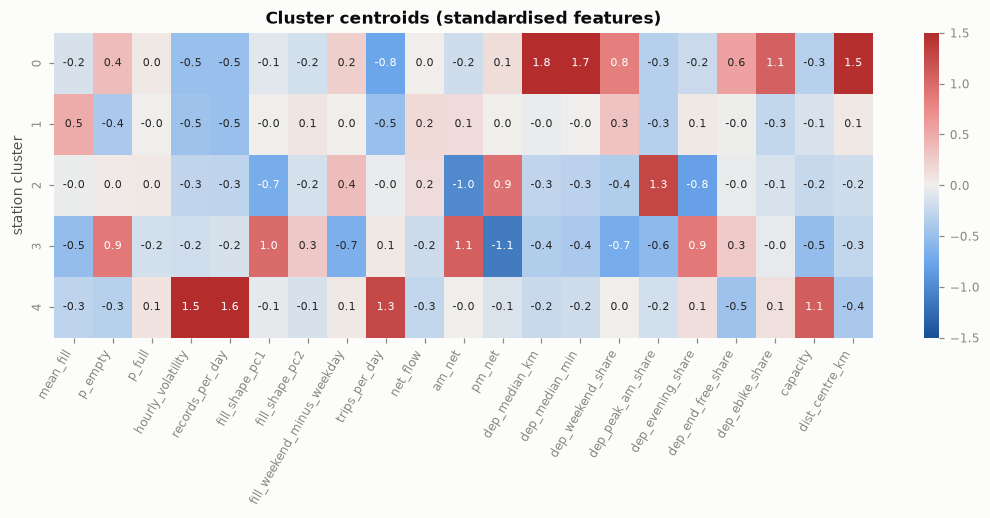

In [20]:
zc = pd.DataFrame(Z, columns=FEATS).groupby(F.station_cluster.values).mean()
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(zc, cmap=bc.DIV, center=0, vmin=-1.5, vmax=1.5, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set(title="Cluster centroids (standardised features)", ylabel="station cluster")
plt.xticks(rotation=60, ha="right")
plt.show()

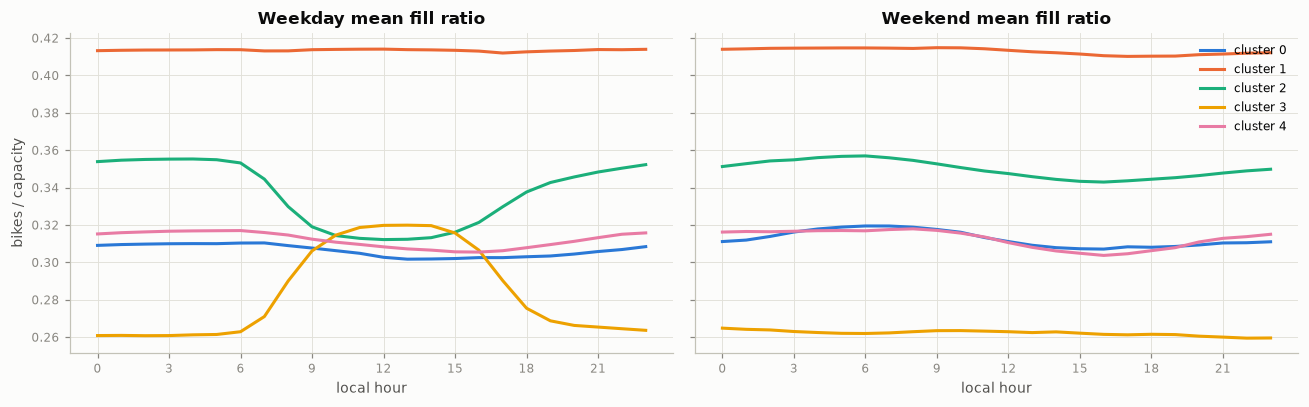

In [21]:
gc = g.merge(F[["station_cluster"]], left_on="station_id", right_index=True)
curves = gc.groupby(["station_cluster", "weekend", "hour"]).fill.mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for w, a in enumerate(ax):
    for c in range(K):
        a.plot(range(24), curves.loc[(c, w)], color=bc.SERIES[c], label=f"cluster {c}")
    a.set(title=["Weekday", "Weekend"][w] + " mean fill ratio", xlabel="local hour", xticks=range(0, 24, 3))
ax[0].set_ylabel("bikes / capacity")
ax[1].legend()
plt.tight_layout()
plt.show()

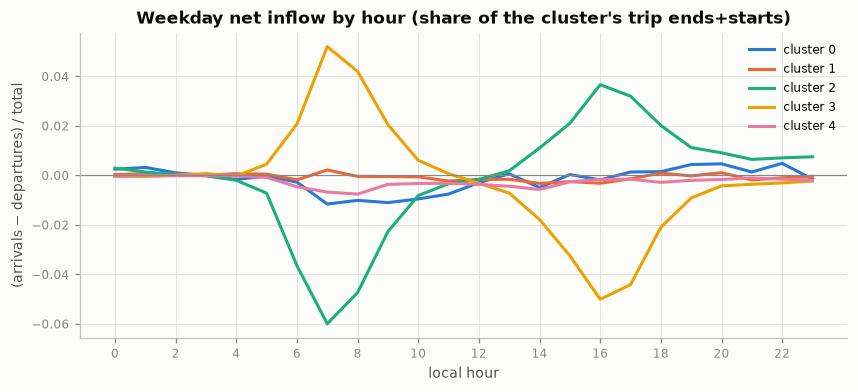

In [22]:
# hourly net flow (arrivals − departures per station per weekday), from trips
trc = tr[tr.weekend == 0]
d_h = trc.groupby(["station_id_start", "hour"]).size()
a_h = trc.groupby(["station_id_end", "end_hour"]).size()
d_h.index.names = a_h.index.names = ["station_id", "hour"]
nf = pd.concat({"d": d_h, "a": a_h}, axis=1).fillna(0).reset_index()
nf = nf.merge(F[["station_cluster"]], left_on="station_id", right_index=True)
nfc = nf.groupby(["station_cluster", "hour"])[["a", "d"]].sum()
nfc = (nfc.a - nfc.d) / nfc.groupby(level=0).transform("sum").sum(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in range(K):
    ax.plot(range(24), nfc.loc[c].reindex(range(24), fill_value=0), color=bc.SERIES[c], label=f"cluster {c}")
ax.axhline(0, color=bc.GREY, lw=.8)
ax.set(title="Weekday net inflow by hour (share of the cluster's trip ends+starts)", xlabel="local hour",
       ylabel="(arrivals − departures) / total", xticks=range(0, 24, 2))
ax.legend()
plt.show()

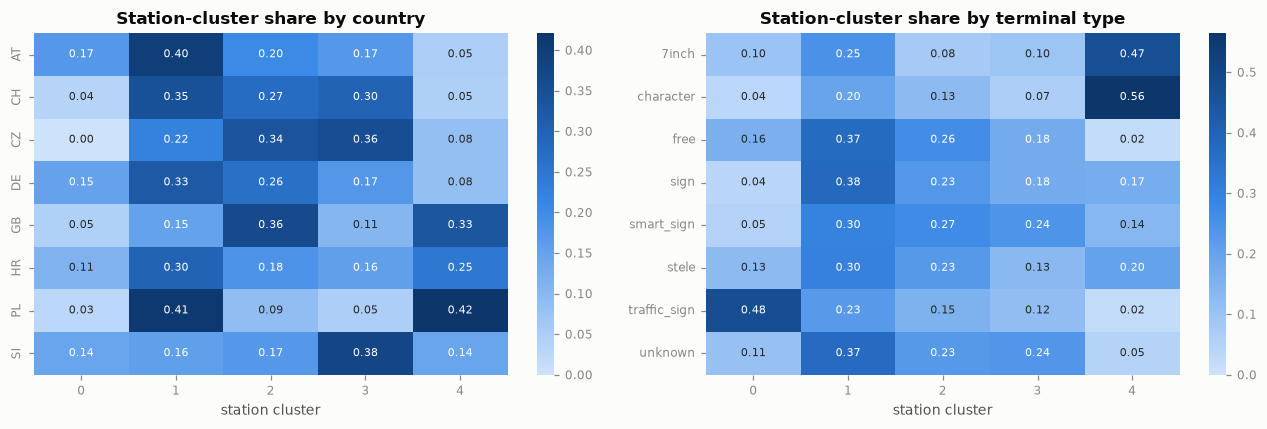

In [23]:
# composition by country and by terminal type
F["country"] = F.city_id.map(cities.country)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
top_c = F.country.value_counts().index[:8]
sns.heatmap(pd.crosstab(F.loc[F.country.isin(top_c), "country"], F.loc[F.country.isin(top_c), "station_cluster"], normalize="index"),
            cmap=bc.SEQ, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax[0], vmin=0)
ax[0].set(title="Station-cluster share by country", ylabel="", xlabel="station cluster")
tt = F.terminal_type.fillna("unknown")
top_t = tt.value_counts().index[:8]
sns.heatmap(pd.crosstab(tt[tt.isin(top_t)], F.loc[tt.isin(top_t), "station_cluster"], normalize="index"),
            cmap=bc.SEQ, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax[1], vmin=0)
ax[1].set(title="Station-cluster share by terminal type", ylabel="", xlabel="station cluster")
plt.tight_layout()
plt.show()

In [24]:
# how many systems mix several station types? (cities with >= 15 clustered stations)
cm = pd.crosstab(F.city_id, F.station_cluster)
cm = cm[cm.sum(axis=1) >= 15]
ent = cm.div(cm.sum(axis=1), axis=0).apply(lambda r: -(r[r > 0] * np.log(r[r > 0])).sum() / np.log(K), axis=1)
print(len(cm), "cities | median normalised entropy of cluster mix:", ent.median().round(3))
print("Cramér's V (city vs station cluster):",
      round(np.sqrt(chi2_contingency(pd.crosstab(F.city_id, F.station_cluster))[0] / (len(F) * (K - 1))), 3))

48 cities | median normalised entropy of cluster mix: 0.711
Cramér's V (city vs station cluster): 0.532


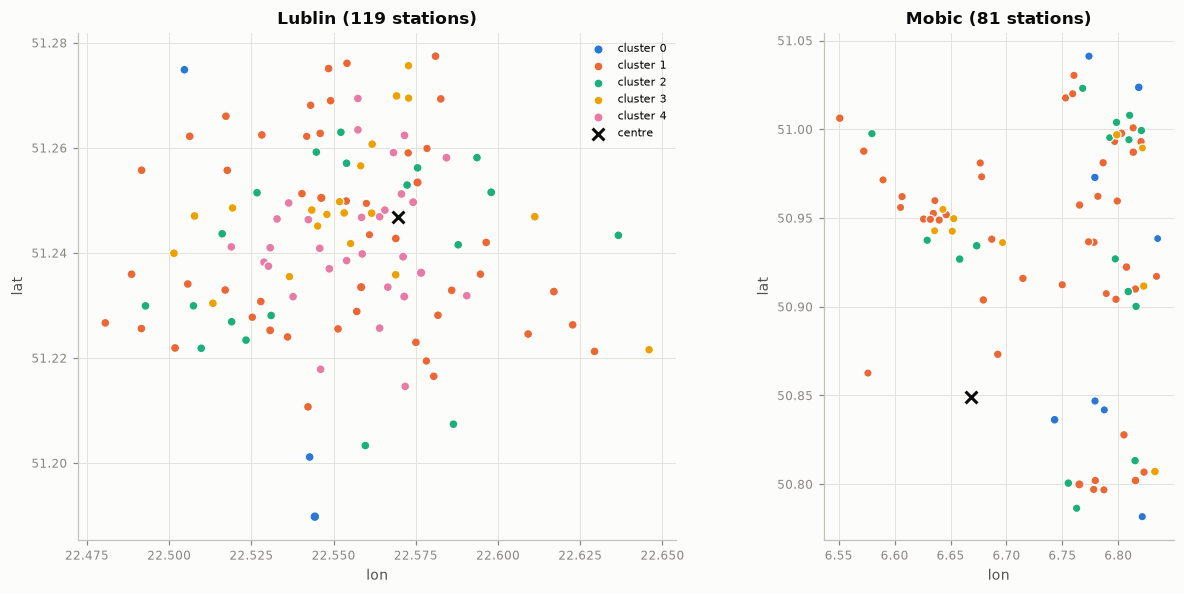

In [25]:
# maps of the two systems with the most clustered stations
top_city = F.city_id.value_counts().index[:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, cid in zip(ax, top_city):
    d = F[F.city_id == cid]
    for c in range(K):
        m = d[d.station_cluster == c]
        a.scatter(m.lon, m.lat, s=22 + 3 * np.sqrt(m.capacity), color=bc.SERIES[c], label=f"cluster {c}",
                  edgecolor="#fcfcfb", linewidth=.8)
    a.scatter(cities.loc[cid, "lon"], cities.loc[cid, "lat"], marker="x", color="#0b0b0b", s=60, label="centre")
    a.set(title=f"{cities.loc[cid, 'name']} ({len(d)} stations)", xlabel="lon", ylabel="lat")
    a.set_aspect(1 / np.cos(np.radians(d.lat.mean())))
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

_Team notes:_

## 7. Linking trip profiles (Part A) and station profiles (Part B)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Trip cluster × start-station cluster crosstab with χ², Cramér's V and lift; origin–destination matrix between station clusters.

**Not done by Claude**
- Only the start station is crossed with trip clusters (no end-station × trip-cluster table).
- No model of the relationship beyond the contingency analysis.

trips whose start station is clustered: 0.851
chi2=66070, dof=20, p=0, Cramér's V=0.129


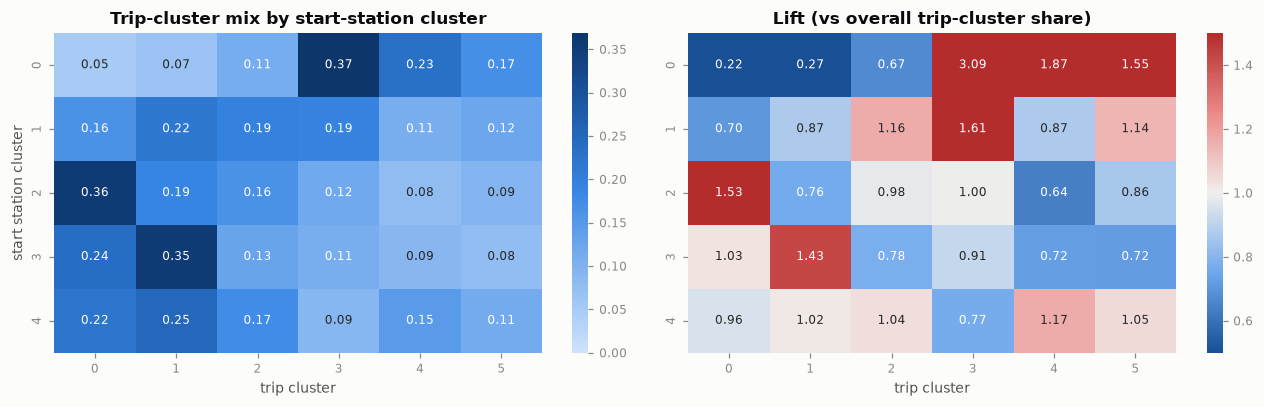

In [26]:
lab = F.station_cluster
tc = trip_cl.assign(start_sc=trip_cl.station_id_start.map(lab), end_sc=trip_cl.station_id_end.map(lab))
both = tc.dropna(subset=["start_sc"])
print("trips whose start station is clustered:", round(len(both) / len(tc), 3))
ct = pd.crosstab(both.start_sc.astype(int), both.trip_cluster)
chi2, p, dof, _ = chi2_contingency(ct)
print(f"chi2={chi2:.0f}, dof={dof}, p={p:.2g}, Cramér's V={np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), cmap=bc.SEQ, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax[0], vmin=0)
ax[0].set(title="Trip-cluster mix by start-station cluster", xlabel="trip cluster", ylabel="start station cluster")
# lift = observed share / overall share
lift = ct.div(ct.sum(axis=1), axis=0) / (ct.sum(axis=0) / ct.values.sum())
sns.heatmap(lift, cmap=bc.DIV, center=1, vmin=0.5, vmax=1.5, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax[1])
ax[1].set(title="Lift (vs overall trip-cluster share)", xlabel="trip cluster", ylabel="")
plt.tight_layout()
plt.show()

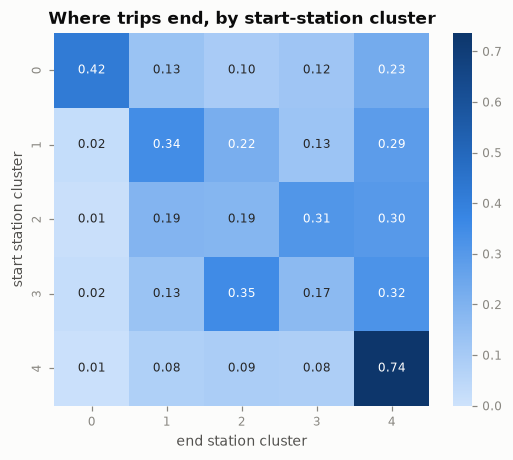

In [27]:
# origin-destination flows between station clusters
od = tc.dropna(subset=["start_sc", "end_sc"])
odm = pd.crosstab(od.start_sc.astype(int), od.end_sc.astype(int), normalize="index")
fig, ax = plt.subplots(figsize=(5.5, 4.4))
sns.heatmap(odm, cmap=bc.SEQ, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax, vmin=0)
ax.set(title="Where trips end, by start-station cluster", xlabel="end station cluster", ylabel="start station cluster")
plt.show()

_Team notes:_

## 8. Save labels (unclustered stations = −1)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Saved `station_clusters.pkl` (used as a feature in 04/05) and `station_features.pkl`.

In [28]:
labels = pd.DataFrame({"station_id": meta.index}).merge(
    F[["station_cluster"]], left_on="station_id", right_index=True, how="left").fillna({"station_cluster": -1})
labels["station_cluster"] = labels.station_cluster.astype(int)
bc.save_clean(labels, "station_clusters")
bc.save_clean(F.reset_index(), "station_features")
labels.station_cluster.value_counts().sort_index()

station_cluster
-1    663
 0    224
 1    756
 2    474
 3    380
 4    435
Name: count, dtype: int64